# t-SNE — Visualizing High-Dimensional Data

Draw high-dimensional data, such as embeddings, as a 2-D map where similar points sit together.

## What's in this notebook

- 1\. What is t-SNE for?
- 2\. How t-SNE works
- 3\. t-SNE on handwritten digits
- 4\. Perplexity
- 5\. How to read a t-SNE plot (and how to misread it)
- 6\. Limitations
- 7\. PCA vs t-SNE vs UMAP
- 8\. Key parameters
- 9\. Interview questions
- 10\. In my own words

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import procrustes

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

# NumPy 2.2 + Apple Accelerate prints harmless "encountered in matmul" RuntimeWarnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

# 1. WHAT IS t-SNE FOR?

t-SNE (t-distributed Stochastic Neighbor Embedding) turns points with many features into points on a 2-D (or 3-D) map.
Points that are neighbours in the original space stay neighbours on the map.

- **nonlinear:** it can pull apart curved, tangled groups that a linear method like PCA lays on top of each other
- **unsupervised:** it never sees labels; we use labels only to colour the plot afterwards
- **for looking, not for modelling:** it is a visualization tool, not a preprocessing step (section 6)

The GenAI use: plot the **embeddings** of documents, chunks or images (hundreds or thousands of numbers each) in 2-D,
to see whether similar items group together and to spot outliers, duplicates or mislabelled items. UMAP is used for the same job.

# 2. HOW t-SNE WORKS

```text
1. High-D: put a Gaussian around each point and turn distances into neighbour probabilities P (near = high, far ≈ 0).
   Each Gaussian's width is tuned so it covers about `perplexity` neighbours: narrow in dense regions, wide in sparse ones.
   The probabilities are made symmetric (p_ij = p_ji), so this is "who is near whom".
2. Lay the points out in 2-D (sklearn starts from a PCA layout).
3. 2-D: turn distances into probabilities Q the same way, but with a heavy-tailed Student-t curve.
4. Move the 2-D points by gradient descent until Q matches P, i.e. minimize the KL divergence KL(P‖Q).
```

**Why a heavy tail.** 2-D has far less room than the original space, so with a Gaussian curve moderately distant points get squashed together
(the **crowding problem**). A Student-t with 1 degree of freedom, which is the Cauchy distribution, lets them sit further apart and leaves gaps between groups:

```text
2-D similarity ∝ 1 / (1 + distance²)        falls off much more slowly than a Gaussian curve, ∝ exp(−distance²)
```

**Why KL(P‖Q) keeps neighbours, not distances.** KL(P‖Q) = Σ p_ij · log(p_ij / q_ij) is asymmetric. Drawing true neighbours far apart
(p large, q small) costs a lot; drawing distant points close together (p small, q large) costs little. So t-SNE works hard to keep
neighbourhoods and barely cares about large distances.

**Optimization.** For the first 250 steps, **early exaggeration** multiplies P by 12, so neighbours pull together hard and clusters form early.
Then it runs normally, up to `max_iter` steps in total (1,000 by default).

# 3. t-SNE ON HANDWRITTEN DIGITS

`load_digits`: 1,797 images of 8×8 pixels, so each image is a point with 64 features.
The usual recipe is **PCA to 30–50 dimensions first, then t-SNE**: PCA removes noise and makes the neighbour search cheaper.
The pixels all share one 0–16 scale, so no scaling is needed here; scale tabular features with different units first.

Left: PCA straight to 2-D. Right: PCA to 30-D, then t-SNE to 2-D. The colours (the true digit) are added after the fit.

PCA keeps 96% of the variance in 30 dims; t-SNE took 2.4 s


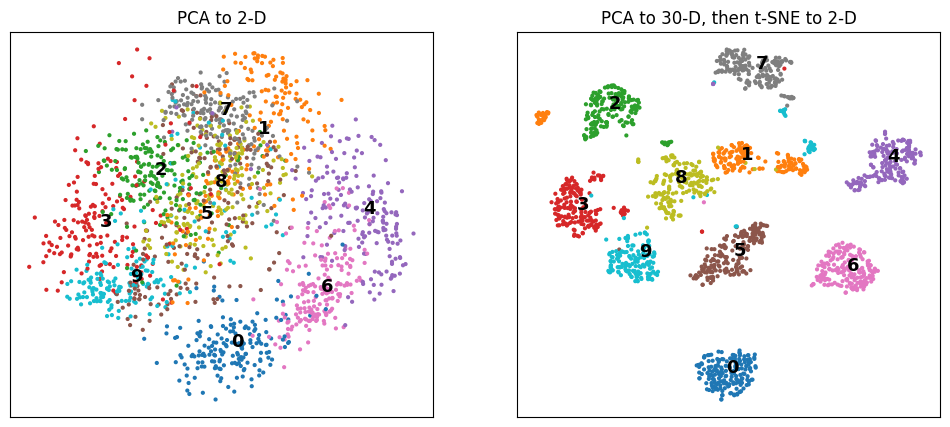

In [2]:
X, y = load_digits(return_X_y=True)


def plot_map(ax, points, title):
    ax.scatter(points[:, 0], points[:, 1], c=y, cmap="tab10", s=4)
    for digit in range(10):
        ax.text(*np.median(points[y == digit], axis=0), str(digit), fontsize=13, weight="bold")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


pca30 = PCA(n_components=30, random_state=42).fit(X)
X30 = pca30.transform(X)
X_pca2 = PCA(n_components=2).fit_transform(X)
start = time.perf_counter()
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X30)
print(f"PCA keeps {pca30.explained_variance_ratio_.sum():.0%} of the variance in 30 dims; t-SNE took {time.perf_counter() - start:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_map(axes[0], X_pca2, "PCA to 2-D")
plot_map(axes[1], X_tsne, "PCA to 30-D, then t-SNE to 2-D")
plt.show()

PCA keeps only its 2 widest directions: 0, 4 and 6 sit at the edges and the other digits pile up in the middle.
t-SNE puts each digit in its own island. Digit 1 even splits into several. A few small specks sit away from their own digit: with labels as colours, those are the points worth a closer look.

In [3]:
def same_digit_neighbour(points):
    _, idx = NearestNeighbors(n_neighbors=2).fit(points).kneighbors(points)
    return (y[idx[:, 1]] == y).mean()          # idx[:, 0] is the point itself


for name, points in [("original 64-D", X), ("PCA 2-D", X_pca2), ("t-SNE 2-D", X_tsne)]:
    print(f"{name:14s} nearest neighbour is the same digit: {same_digit_neighbour(points):.1%}")

original 64-D  nearest neighbour is the same digit: 98.8%
PCA 2-D        nearest neighbour is the same digit: 58.7%
t-SNE 2-D      nearest neighbour is the same digit: 98.9%


A point's nearest neighbour is the same digit **98.8%** of the time in the original 64-D space and **98.9%** on the t-SNE map,
but only **58.7%** after PCA to 2-D. t-SNE kept the neighbourhoods; a 2-D PCA projection lost them.

# 4. PERPLEXITY

Perplexity is roughly **the number of neighbours each point pays attention to** (formally, 2 to the power of the entropy of a point's neighbour probabilities).
The default is 30, sklearn suggests 5–50, larger datasets usually need a larger value, and it must be smaller than the number of points.

- **low:** only the closest few points count, so the map breaks into many tiny clumps and the big groups get lost
- **high:** bigger neighbourhoods, so bigger, smoother islands and more of the overall layout, but slower

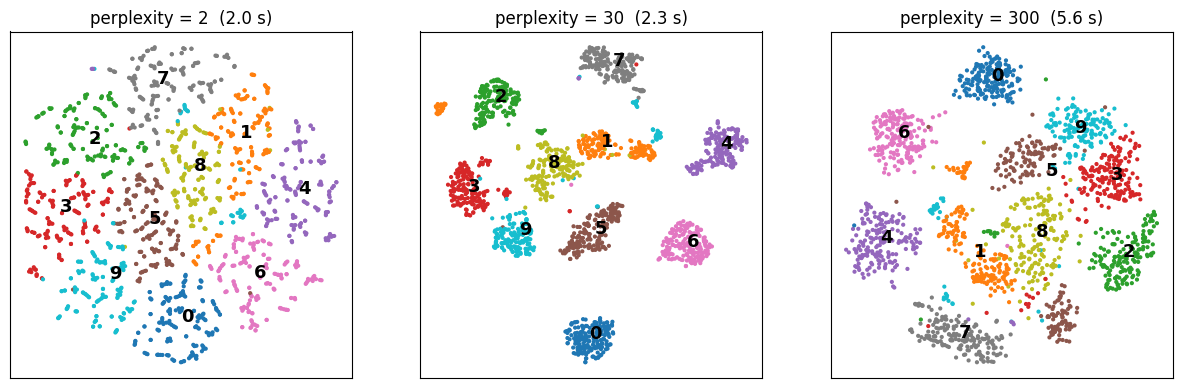

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, perplexity in zip(axes, [2, 30, 300]):
    start = time.perf_counter()
    points = TSNE(perplexity=perplexity, random_state=42).fit_transform(X30)
    plot_map(ax, points, f"perplexity = {perplexity}  ({time.perf_counter() - start:.1f} s)")
plt.show()

At 2 the map is one big disc of loose points: each digit has a rough region, but there are no gaps between digits.
At 30 every digit is a tight, separate island. At 300 the islands get wider and move closer together, and the run takes two to three times as long as at 30 (see the titles).
There is no single right value: try a few and trust the structure that shows up in all of them.

# 5. HOW TO READ A t-SNE PLOT (AND HOW TO MISREAD IT)

| You can trust | You can't trust |
|---|---|
| which points are neighbours | the size of a cluster |
| that a group stands apart from the rest | the distance between two clusters |
| a point sitting inside another group's island (worth a look) | the axes and the orientation (they mean nothing) |
| | small clusters at low perplexity (noise can make them) |

**Cluster size.** t-SNE adapts each point's neighbourhood to the local density, so it expands dense clusters and shrinks sparse ones.
Below, cluster B is 10× wider than cluster A in the original space.

In [5]:
rng = np.random.default_rng(0)
tight = rng.normal(0, 1, size=(300, 10))           # cluster A
wide = rng.normal(0, 10, size=(300, 10)) + 100     # cluster B: 10x the spread, far from A
two_clusters = TSNE(random_state=42).fit_transform(np.vstack([tight, wide]))


def spread(points):
    return np.linalg.norm(points - points.mean(axis=0), axis=1).mean()   # mean distance to the centre


print(f"original space: A spread = {spread(tight):.1f}   B spread = {spread(wide):.1f}")
print(f"t-SNE map:      A spread = {spread(two_clusters[:300]):.1f}   B spread = {spread(two_clusters[300:]):.1f}")

original space: A spread = 3.1   B spread = 30.7
t-SNE map:      A spread = 8.4   B spread = 8.4


B is 10× wider than A in the original space (30.7 vs 3.1), but on the map both have a spread of about 8.4.
A big cluster on a t-SNE plot is not necessarily a spread-out group, and a small one is not necessarily a tight group.

**Noise.** Below are 500 points of pure random noise (100-D Gaussian): there are no clusters to find.

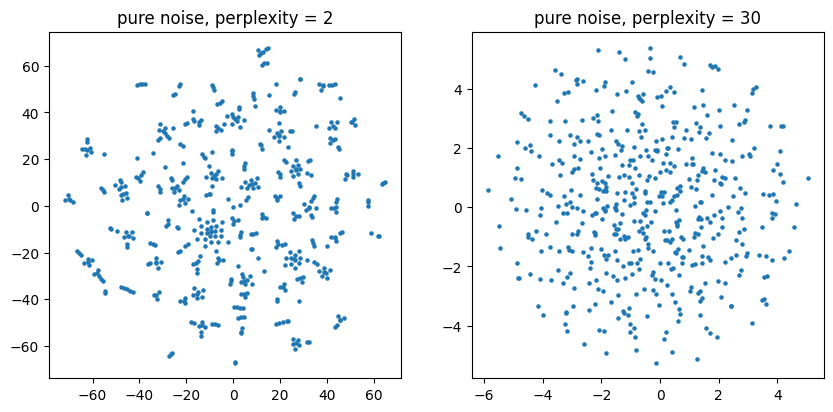

In [6]:
noise = np.random.default_rng(0).normal(size=(500, 100))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, perplexity in zip(axes, [2, 30]):
    points = TSNE(perplexity=perplexity, random_state=42).fit_transform(noise)
    ax.scatter(points[:, 0], points[:, 1], s=5)
    ax.set_title(f"pure noise, perplexity = {perplexity}")
plt.show()

At perplexity 2 the noise falls into dozens of small, tight clumps that look like real clusters. At 30 it is one even blob, which is the honest picture.
Before believing small clusters, re-run with a higher perplexity and check that they survive.

# 6. LIMITATIONS

- **No `transform()`.** sklearn's `TSNE` only has `fit_transform()`, so it can't place new points on an existing map.
  Adding a point means re-running on everything, which gives a new map. That is why t-SNE isn't used as a feature step
  before a model: there is no way to embed the test set or live requests.
- **Slow.** Exact t-SNE compares every pair of points: O(N²). sklearn's default `method="barnes_hut"` summarizes groups of
  far-away points: O(N log N), but it works only for 2 or 3 output dimensions.
- **Random.** The map depends on the seed, the start layout and perplexity. Set `random_state` to get the same map again.

In [7]:
print("PCA has transform():", hasattr(PCA(), "transform"), "   TSNE has transform():", hasattr(TSNE(), "transform"))

for method in ["barnes_hut", "exact"]:
    start = time.perf_counter()
    TSNE(method=method, random_state=42).fit_transform(X30)
    print(f"method = {method:10s} {time.perf_counter() - start:5.1f} s on {len(X30):,} points")

PCA has transform(): True    TSNE has transform(): False


method = barnes_hut   2.5 s on 1,797 points


method = exact       32.4 s on 1,797 points


PCA has `transform()`; `TSNE` doesn't. Even on 1,797 points, exact t-SNE took about 30 s, against a few seconds for Barnes-Hut.
Its cost grows with N², so doubling the data roughly quadruples the time. Keep the default; for hundreds of thousands of points, sample the data or use UMAP.

Below, the same data with two seeds. `procrustes` shifts, scales, rotates and flips one map onto the other;
its score is 0 if the two then have the same shape, and 1 at most.

init='pca'     seed 0 vs seed 1, shape difference = 0.0005
init='random'  seed 0 vs seed 1, shape difference = 0.7165


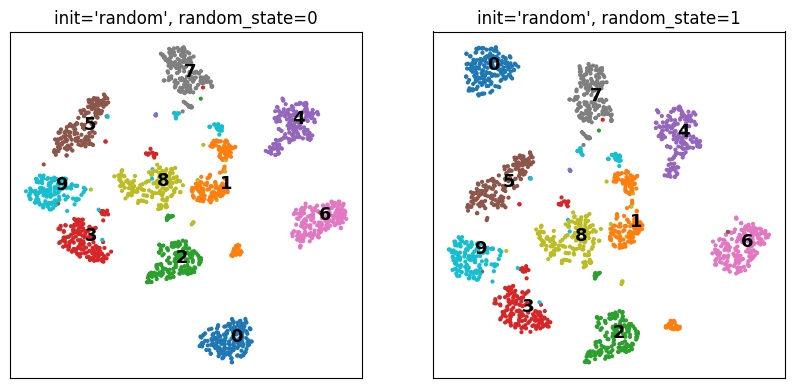

In [8]:
maps = {(init, seed): TSNE(init=init, random_state=seed).fit_transform(X30) for init in ["pca", "random"] for seed in [0, 1]}
for init in ["pca", "random"]:
    print(f"init={init!r:9s} seed 0 vs seed 1, shape difference = {procrustes(maps[init, 0], maps[init, 1])[2]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_map(axes[0], maps["random", 0], "init='random', random_state=0")
plot_map(axes[1], maps["random", 1], "init='random', random_state=1")
plt.show()

With `init="random"` the two seeds give clearly different maps (shape difference 0.72): digit 0 is at the bottom in one and at the top left in the other,
though each island still holds the same digit. With the default `init="pca"` the seed hardly matters (0.0005), because the start layout comes from PCA.
Either way, set `random_state`, and never read meaning into where an island ends up.

# 7. PCA VS t-SNE VS UMAP

| | PCA | t-SNE | UMAP |
|---|---|---|---|
| Type | linear | nonlinear | nonlinear |
| Keeps | the directions of largest variance (global structure) | local neighbours | local neighbours, often more of the overall layout |
| Speed | fast | slow on large data | usually faster than t-SNE on large data |
| Embeds new points (`transform`) | yes | no | yes |
| Main use | preprocessing, features, a first look | 2-D plots | 2-D plots; also shrinking embeddings before clustering (BERTopic) |

None of the three needs labels. LDA (previous notebook) does: it uses labels to find directions that separate the classes.

# 8. KEY PARAMETERS

| Parameter | Default | What it does |
|---|---|---|
| `n_components` | 2 | output dimensions: 2 or 3 (Barnes-Hut allows at most 3) |
| `perplexity` | 30.0 | roughly the number of neighbours per point; try 5–50; must be below the number of points |
| `metric` | `"euclidean"` | distance in the original space; `"cosine"` is common for text embeddings |
| `init` | `"pca"` | start layout; more stable than `"random"` |
| `learning_rate` | `"auto"` | gradient-descent step size; auto = max(N / early_exaggeration / 4, 50). Too high: a "ball" of evenly spaced points; too low: one dense cloud with a few outliers |
| `max_iter` | 1000 | total gradient-descent steps, at least 250 (called `n_iter` before sklearn 1.5) |
| `early_exaggeration` | 12.0 | for the first 250 steps, multiplies P so neighbours pull together harder and clusters form early; larger = more space between clusters |
| `method` | `"barnes_hut"` | O(N log N) approximation; `"exact"` is O(N²) |
| `random_state` | None | fix it to get the same map again |

# 9. INTERVIEW QUESTIONS

### Q1. Explain t-SNE in 30 seconds.
t-SNE is a nonlinear, unsupervised method for drawing high-dimensional data in 2-D. It turns distances into neighbour probabilities
(Gaussian in the original space, heavy-tailed Student-t in 2-D) and moves the 2-D points by gradient descent to minimize KL(P‖Q),
so points that were neighbours stay neighbours. It keeps local neighbourhoods, not cluster sizes or distances between clusters,
and has no `transform()` for new points, so it is used to look at data such as embeddings, not to build features.

### Q2. How does t-SNE measure similarity in the original space and on the map?
Original space: a Gaussian around each point, with its width tuned so it covers about `perplexity` neighbours (narrow where the data is dense).
Map: a Student-t with 1 degree of freedom. Both are turned into probabilities, P and Q.

### Q3. Why a Student-t in 2-D instead of a Gaussian?
The crowding problem: 2-D has much less room than the original space, so with a Gaussian, moderately distant points get squashed together.
A Student-t with 1 degree of freedom (the Cauchy distribution) has heavy tails, so those points can sit further apart and the clusters separate.

### Q4. What does t-SNE minimize, and why does the direction of the KL divergence matter?
KL(P‖Q) between the neighbour probabilities of the original space (P) and of the map (Q). It is asymmetric: separating true neighbours
(p large, q small) is expensive, putting distant points close (p small, q large) is cheap. That is why local structure is kept and global distances are not.

### Q5. What is perplexity, and what if it is too low or too high?
Roughly the number of neighbours each point considers (default 30, usually 5–50; bigger datasets usually need more). Too low: many tiny clumps,
even from pure noise. Too high: local detail blurs and it runs slower. Check that the structure holds across a few values.

### Q6. What do early exaggeration, learning rate and max_iter do?
Early exaggeration multiplies P (×12) for the first 250 steps so clusters form early. The learning rate is the gradient-descent step size
(`"auto"` scales it with N); too high gives a ball of evenly spaced points, too low a dense cloud. `max_iter` is the number of steps (1,000).

### Q7. What does a t-SNE plot preserve, and what doesn't it?
It preserves who is near whom. It doesn't preserve cluster sizes (dense clusters get expanded, sparse ones shrunk), distances between clusters,
or any meaning in the axes.

### Q8. Does t-SNE use labels?
No. It is unsupervised; labels are used only afterwards, to colour the plot.

### Q9. Can you use t-SNE output as features for a classifier?
Not in practice. sklearn's `TSNE` has no `transform()`, so test data or live requests can't be placed on the map;
you would have to re-run on everything and get a different map. Use PCA, UMAP or the embeddings themselves.

### Q10. Why run PCA before t-SNE?
It removes noise and makes the neighbour search faster. For data with many features, reduce to about 50 dimensions
with PCA (TruncatedSVD for sparse data), then run t-SNE.

### Q11. What is the time complexity of t-SNE?
Exact t-SNE is O(N²): it compares every pair of points. sklearn's default Barnes-Hut approximation is O(N log N) and supports
at most 3 output dimensions. For millions of points, sample the data or use UMAP.

### Q12. Two runs give different pictures. Is something wrong?
No. The cost function is not convex, so a different seed or start layout can put the islands in different places,
rotated or flipped, while the neighbourhoods stay mostly the same. Set `random_state`; the default `init="pca"` is more stable.

### Q13. How would you visualize the embeddings of a RAG document store?
Take a sample of chunk embeddings, optionally PCA to 50 dimensions, run t-SNE or UMAP with cosine distance, and colour by source or topic.
Look for topics that form islands, outliers and near-duplicates. Don't read meaning into the sizes of islands or the distances between them.

### Q14. PCA vs t-SNE vs UMAP (vs LDA)?
PCA is linear, fast, has `transform()` and keeps the largest-variance directions: use it for preprocessing.
t-SNE is nonlinear and keeps local neighbours, with no `transform()`: use it for 2-D plots. UMAP is similar to t-SNE but usually faster,
has `transform()` and often keeps more of the overall layout. LDA is the supervised one: it uses labels to find directions that separate the classes.

# 10. IN MY OWN WORDS

Write this from memory, without looking above:

- What t-SNE does, step by step:
- What perplexity controls:
- What I can and can't read from a t-SNE plot:
- Why t-SNE isn't used as a feature step:
- How I would use it on embeddings: